# Sección 5.8.3 — Prueba de concepto *in silico* de la arquitectura híbrida

Notebook reproducible para la demostración computacional del esquema:

\[
P_{híbrido}(t)=P_{base}(t)+\hat e_{GP}(t)
\]

Se utiliza un modelo Gaussiano Doble como modelo base y un Proceso Gaussiano para aprender una discrepancia sintética conocida.

> Esta prueba es estrictamente **de concepto** y no puede considerarse una validación experimental del escalamiento a biorreactor.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

np.set_printoptions(precision=8, suppress=True)
pd.set_option("display.precision", 8)

## 1. Datos cinéticos de referencia

In [ ]:
t_P = np.array([0,12,24,36,48,60,72,84,96], dtype=float)

P = np.array([
    0.00000,0.08808,0.10395,0.01175,0.03019,
    0.18280,0.15532,0.08044,0.04960
], dtype=float)

## 2. Modelo Gaussiano Doble base

In [ ]:
def gaussiano_doble(t, A1, mu1, sigma1, A2, mu2, sigma2):
    t = np.asarray(t, dtype=float)
    return (
        A1*np.exp(-((t-mu1)**2)/(2*sigma1**2))
        + A2*np.exp(-((t-mu2)**2)/(2*sigma2**2))
    )

p0 = [0.12,20,7,0.18,68,12]
bounds = (
    [0.0,5.0,1.0,0.0,45.0,1.0],
    [1.0,35.0,30.0,1.0,95.0,40.0]
)

popt_GD, _ = curve_fit(
    gaussiano_doble,
    t_P,
    P,
    p0=p0,
    bounds=bounds,
    maxfev=200000
)

P_fit = gaussiano_doble(t_P, *popt_GD)
r2_GD = r2_score(P, P_fit)
rmse_GD = np.sqrt(mean_squared_error(P, P_fit))

print(f"R²   = {r2_GD:.6f}")
print(f"RMSE = {rmse_GD:.6f} mg/L")
print("Parámetros:", popt_GD)

R²   = 0.903875
RMSE = 0.018286 mg/L
Parámetros: [ 0.15983429 18.47186302  5.92447759  0.18464359 67.49953534 12.8029743 ]


## 3. Generación del escenario sintético

Se introducen deliberadamente en el segundo componente:

- +10 % en amplitud.
- +12 h de desplazamiento temporal.
- +20 % en dispersión temporal.
- Ruido gaussiano con σ = 0.01 mg/L.

Estas perturbaciones son exclusivamente computacionales y no representan estimaciones experimentales del comportamiento real en biorreactor.

In [ ]:
np.random.seed(42)

t_bio = np.linspace(0,100,25)

# Predicción del modelo base
P_base = gaussiano_doble(t_bio, *popt_GD)

A1, m1, s1, A2, m2, s2 = popt_GD

# Trayectoria sintética
P_sint_real = gaussiano_doble(
    t_bio,
    A1, m1, s1,
    A2*1.10,
    m2+12.0,
    s2*1.20
)

ruido = np.random.normal(0,0.01,size=len(t_bio))
P_sint_obs = np.clip(P_sint_real + ruido, 0, None)

# Error residual
error_residual = P_sint_obs - P_base

print("Escenario sintético generado.")

Escenario sintético generado.


## 4. Ajuste del Proceso Gaussiano al residuo

In [ ]:
kernel = C(1.0, (1e-3,1e3)) * RBF(10.0, (1e-2,1e2))

gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=0.005,
    n_restarts_optimizer=10,
    random_state=42
)

gp.fit(t_bio.reshape(-1,1), error_residual)

print("Kernel optimizado:")
print(gp.kernel_)

Kernel optimizado:
0.0476**2 * RBF(length_scale=14.7)


## 5. Predicción híbrida

In [ ]:
t_pred = np.linspace(0,100,500)

e_GP_pred, e_GP_std = gp.predict(
    t_pred.reshape(-1,1),
    return_std=True
)

P_base_pred = gaussiano_doble(t_pred, *popt_GD)
P_hibrido = P_base_pred + e_GP_pred

## 6. Figura 5.14 — Arquitectura híbrida

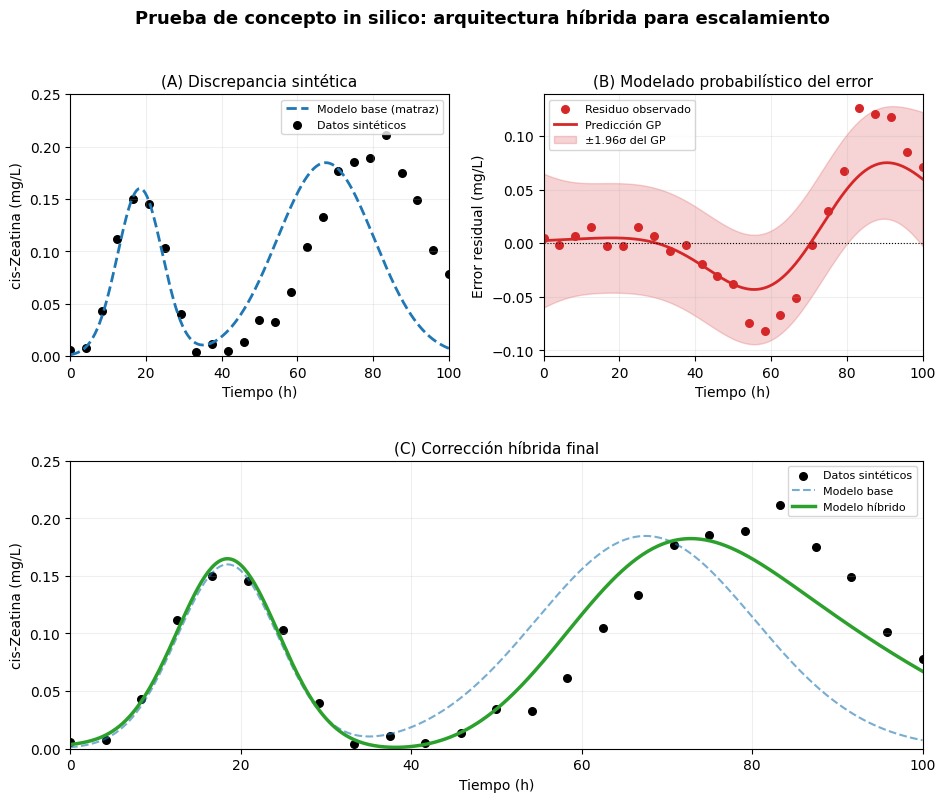

In [ ]:
fig = plt.figure(figsize=(11,8.5))

gs = fig.add_gridspec(
    2,2,
    height_ratios=[1,1.1],
    hspace=0.38,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[1,:])

# Panel A
ax1.plot(
    t_pred, P_base_pred,
    color="tab:blue", lw=2, ls="--",
    label="Modelo base (matraz)"
)
ax1.scatter(
    t_bio, P_sint_obs,
    color="black", s=30,
    label="Datos sintéticos"
)
ax1.set_title("(A) Discrepancia sintética", fontsize=11)
ax1.set_xlabel("Tiempo (h)")
ax1.set_ylabel("cis-Zeatina (mg/L)")
ax1.set_xlim(0,100)
ax1.set_ylim(0,0.25)
ax1.grid(alpha=0.2)
ax1.legend(fontsize=8)

# Panel B
ax2.scatter(
    t_bio, error_residual,
    color="tab:red", s=30,
    label="Residuo observado"
)
ax2.plot(
    t_pred, e_GP_pred,
    color="tab:red", lw=2,
    label="Predicción GP"
)
ax2.fill_between(
    t_pred,
    e_GP_pred - 1.96*e_GP_std,
    e_GP_pred + 1.96*e_GP_std,
    color="tab:red", alpha=0.2,
    label="±1.96σ del GP"
)
ax2.axhline(0, color="black", lw=0.8, ls=":")
ax2.set_title("(B) Modelado probabilístico del error", fontsize=11)
ax2.set_xlabel("Tiempo (h)")
ax2.set_ylabel("Error residual (mg/L)")
ax2.set_xlim(0,100)
ax2.grid(alpha=0.2)
ax2.legend(fontsize=8)

# Panel C
ax3.scatter(
    t_bio, P_sint_obs,
    color="black", s=30,
    label="Datos sintéticos"
)
ax3.plot(
    t_pred, P_base_pred,
    color="tab:blue", lw=1.5, ls="--", alpha=0.6,
    label="Modelo base"
)
ax3.plot(
    t_pred, P_hibrido,
    color="tab:green", lw=2.5,
    label="Modelo híbrido"
)
ax3.set_title("(C) Corrección híbrida final", fontsize=11)
ax3.set_xlabel("Tiempo (h)")
ax3.set_ylabel("cis-Zeatina (mg/L)")
ax3.set_xlim(0,100)
ax3.set_ylim(0,0.25)
ax3.grid(alpha=0.2)
ax3.legend(fontsize=8)

fig.suptitle(
    "Prueba de concepto in silico: arquitectura híbrida para escalamiento",
    fontsize=13,
    fontweight="bold",
    y=0.98
)

plt.savefig("Figura_5_14_Framework_Hibrido.png", dpi=300, bbox_inches="tight")
plt.savefig("Figura_5_14_Framework_Hibrido.pdf", bbox_inches="tight")
plt.show()

## 7. Cuantificación de la mejora dentro de muestra

La evaluación se realiza sobre los mismos puntos sintéticos utilizados para entrenar el GP. Por ello, representa una evaluación **dentro de muestra** y no una validación predictiva independiente.

In [ ]:
P_base_25 = gaussiano_doble(t_bio, *popt_GD)
e_GP_25 = gp.predict(t_bio.reshape(-1,1))
P_hibrido_25 = P_base_25 + e_GP_25

r2_base = r2_score(P_sint_obs, P_base_25)
rmse_base = np.sqrt(mean_squared_error(P_sint_obs, P_base_25))

r2_hibrido = r2_score(P_sint_obs, P_hibrido_25)
rmse_hibrido = np.sqrt(mean_squared_error(P_sint_obs, P_hibrido_25))

tabla = pd.DataFrame({
    "Modelo":["Base","Híbrido"],
    "R²":[r2_base,r2_hibrido],
    "RMSE (mg/L)":[rmse_base,rmse_hibrido]
})

display(tabla)

mejora = 100*(rmse_base-rmse_hibrido)/rmse_base
print(f"Reducción del RMSE: {mejora:.2f}%")

,Modelo,R²,RMSE (mg/L)
0,Base,0.25730803,0.05813103
1,Híbrido,0.87560038,0.02379103


Reducción del RMSE: 59.07%


## 8. Interpretación

La prueba demuestra que, bajo un escenario sintético controlado, el Proceso Gaussiano puede aprender una discrepancia conocida y corregir la predicción base.

No demuestra:

- que el comportamiento real del cultivo en biorreactor siga esta desviación;
- que el desplazamiento de 12 h tenga una causa física específica;
- que la arquitectura esté validada experimentalmente;
- ni que el desempeño dentro de muestra represente capacidad de generalización.

La validación del *framework* requiere datos experimentales reales a escala biorreactor.